In [3]:
import sys
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.ticker import StrMethodFormatter
plt.style.use('dark_background')

In [4]:
cwd = Path.cwd()
project_root = cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print('Done!')

Done!


In [5]:
data_path = project_root / 'data' / 'processed' / 'demand_development.csv'
demand_data = pd.read_csv(data_path)

In [6]:
utc_columns = [
    'timestamp_utc',
    'timestamp_london',
    'interval_end_utc',
    'forecast_issue_utc',
    'forecast_cutoff_utc',
    'scheduled_kickoff_utc',
]

for column in utc_columns:
    demand_data[column] = pd.to_datetime(
        demand_data[column], utc=True
    )

In [7]:
demand_data['timestamp_london'] = demand_data['timestamp_utc'].dt.tz_convert('Europe/London')

In [8]:
demand_data['settlement_date'] = pd.to_datetime(
    demand_data['settlement_date']
)

In [9]:
train_set = demand_data.loc[demand_data['data_split'] == 'train'].copy()
train_set = train_set.sort_values(by='timestamp_utc')

In [10]:
train_set.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,forecast_cutoff_utc,neso_available_at_cutoff,Datetime,Publish_Datetime,TRIAD_Avoidance_Estimate,hour_of_week,half_hour_of_week,is_bank_holiday_england_wales,is_bank_holiday_scotland,is_bank_holiday_any_gb,data_split,baseline_fit_eligible,is_england_match_day,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,2022-12-31 10:00:00+00:00,True,2023-01-01T00:30:00Z,2022-12-31T08:45:00Z,0,144,288,False,False,False,train,True,False,NaN,NaN,NaT,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,2022-12-31 10:00:00+00:00,True,2023-01-01T01:00:00Z,2022-12-31T08:45:00Z,0,144,289,False,False,False,train,True,False,NaN,NaN,NaT,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,2022-12-31 10:00:00+00:00,True,2023-01-01T01:30:00Z,2022-12-31T08:45:00Z,0,145,290,False,False,False,train,True,False,NaN,NaN,NaT,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,2022-12-31 10:00:00+00:00,True,2023-01-01T02:00:00Z,2022-12-31T08:45:00Z,0,145,291,False,False,False,train,True,False,NaN,NaN,NaT,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,2022-12-31 10:00:00+00:00,True,2023-01-01T02:30:00Z,2022-12-31T08:45:00Z,0,146,292,False,False,False,train,True,False,NaN,NaN,NaT,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [11]:
demand_series = train_set['demand_mw']
demand_series.index = train_set['timestamp_utc']
demand_series.head()

timestamp_utc
2023-01-01 00:00:00+00:00    20967
2023-01-01 00:30:00+00:00    21699
2023-01-01 01:00:00+00:00    21185
2023-01-01 01:30:00+00:00    20442
2023-01-01 02:00:00+00:00    19633
Name: demand_mw, dtype: int64

In [12]:
demand_series.info()

<class 'pandas.Series'>
DatetimeIndex: 20400 entries, 2023-01-01 00:00:00+00:00 to 2024-02-29 23:30:00+00:00
Series name: demand_mw
Non-Null Count  Dtype
--------------  -----
20400 non-null  int64
dtypes: int64(1)
memory usage: 318.8 KB


In [13]:
demand_series.index.diff().dropna().value_counts()

timestamp_utc
0 days 00:30:00    20399
Name: count, dtype: int64

Change from 30 minutes earlier

In [14]:
first_diff = demand_series.subtract(demand_series.shift(1))
first_diff.head()

timestamp_utc
2023-01-01 00:00:00+00:00      NaN
2023-01-01 00:30:00+00:00    732.0
2023-01-01 01:00:00+00:00   -514.0
2023-01-01 01:30:00+00:00   -743.0
2023-01-01 02:00:00+00:00   -809.0
Name: demand_mw, dtype: float64

In [15]:
print(f'Missing values in first diff: {len(first_diff[first_diff.isna()])}')

Missing values in first diff: 1


Change from 24 elapsed hours earlier

In [16]:
daily_diff = demand_series.subtract(demand_series.shift(48))
daily_diff.tail()

timestamp_utc
2024-02-29 21:30:00+00:00    2462.0
2024-02-29 22:00:00+00:00    2710.0
2024-02-29 22:30:00+00:00    2740.0
2024-02-29 23:00:00+00:00    3059.0
2024-02-29 23:30:00+00:00    3205.0
Name: demand_mw, dtype: float64

In [17]:
print(f'Missing values in daily diff: {len(daily_diff[daily_diff.isna()])}')

Missing values in daily diff: 48


Change from 168 elapsed hours earlier

In [18]:
weekly_diff = demand_series.subtract(demand_series.shift(336))
weekly_diff.tail()

timestamp_utc
2024-02-29 21:30:00+00:00    772.0
2024-02-29 22:00:00+00:00    701.0
2024-02-29 22:30:00+00:00    416.0
2024-02-29 23:00:00+00:00    577.0
2024-02-29 23:30:00+00:00    523.0
Name: demand_mw, dtype: float64

In [19]:
print(f'Missing values in weekly diff: {len(weekly_diff[weekly_diff.isna()])}')

Missing values in weekly diff: 336


verifying the transformations

In [20]:
summary = []
for s in [first_diff, daily_diff, weekly_diff]:
    report = {
        'Number of observations': len(s),
        'Number of missing values': len(s[s.isna()]),
        'Mean': s.mean(),
        'Standard deviation': s.std(),
        'Minimum': s.min(),
        'Maximum': s.max()
    }
    summary.append(report)
    
summary_df = pd.DataFrame(summary)

In [21]:
summary_df.loc[len(summary_df)] = {
        'Number of observations': len(demand_series),
        'Number of missing values': len(demand_series[demand_series.isna()]),
        'Mean': demand_series.mean(),
        'Standard deviation': demand_series.std(),
        'Minimum': demand_series.min(),
        'Maximum': demand_series.max()
    }

In [22]:
summary_df = summary_df.loc[[3, 0, 1, 2]]

In [23]:
summary_df.head()

,Number of observations,Number of missing values,Mean,Standard deviation,Minimum,Maximum
3,20400,0,26663.920588,6213.309192,13598.0,45096.0
0,20400,1,0.233688,911.994437,-2586.0,3754.0
1,20400,48,15.388070,2573.152260,-11077.0,13271.0
2,20400,336,52.991079,2879.511270,-13347.0,17387.0


In [24]:
summary_df.index = pd.Series(['Raw demand', 'First difference', 'Daily difference', 'Weekly difference'])

In [25]:
summary_df.head()

,Number of observations,Number of missing values,Mean,Standard deviation,Minimum,Maximum
Raw demand,20400,0,26663.920588,6213.309192,13598.0,45096.0
First difference,20400,1,0.233688,911.994437,-2586.0,3754.0
Daily difference,20400,48,15.388070,2573.152260,-11077.0,13271.0
Weekly difference,20400,336,52.991079,2879.511270,-13347.0,17387.0


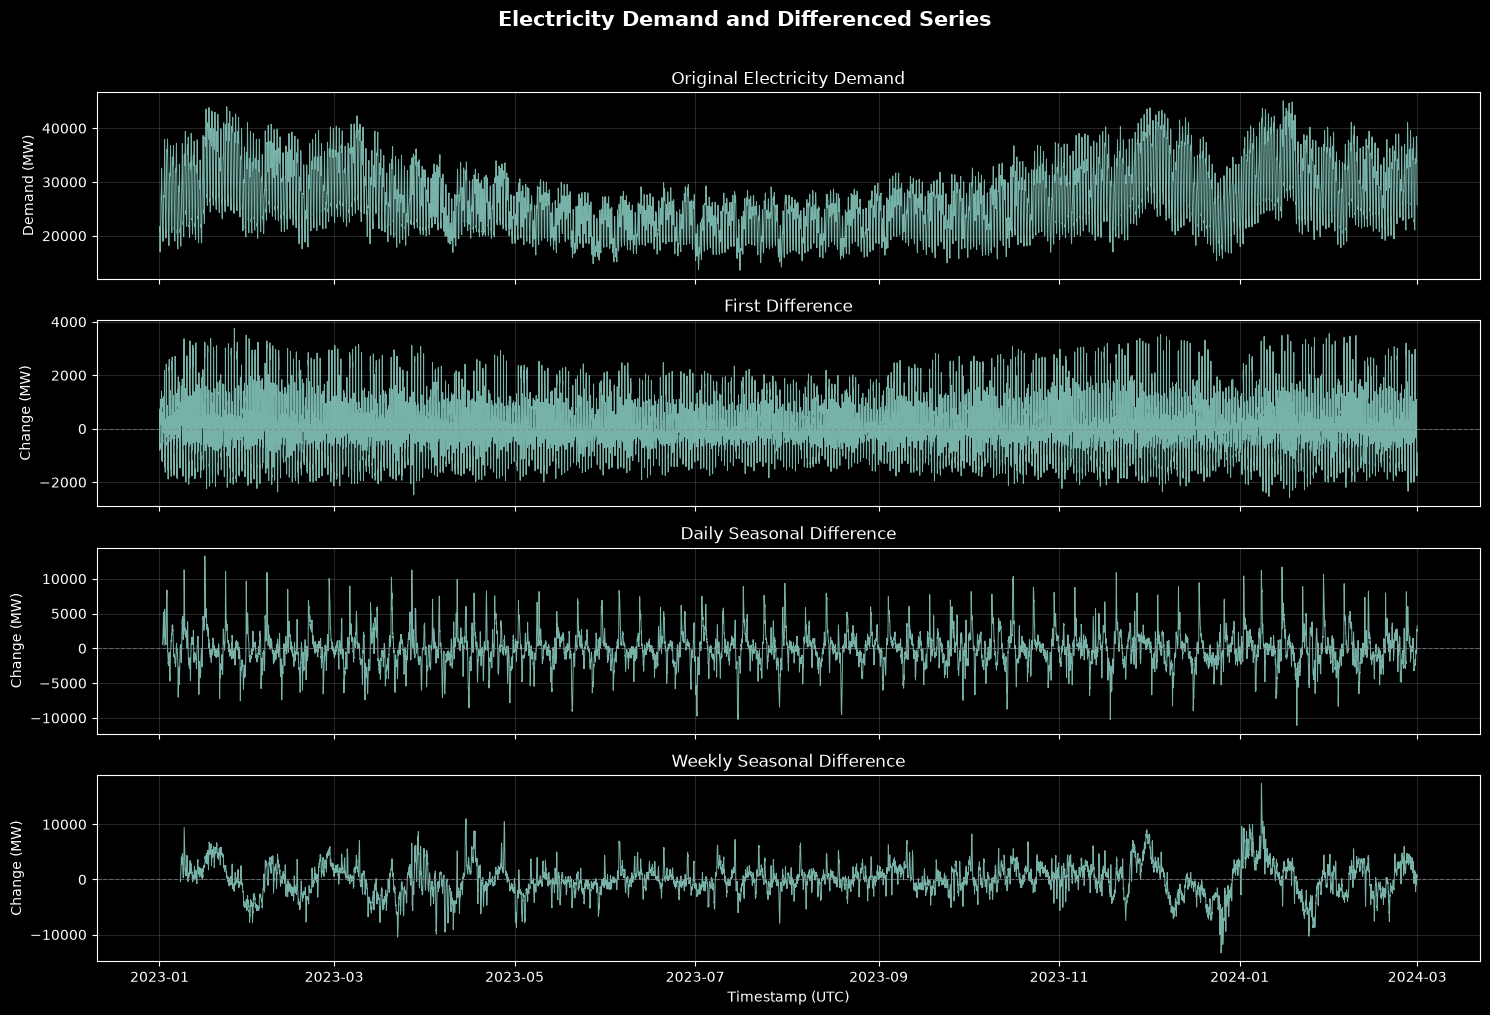

In [26]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 10),
    sharex=True
)

series = [
    (demand_series, 'Original Electricity Demand'),
    (first_diff, 'First Difference'),
    (daily_diff, 'Daily Seasonal Difference'),
    (weekly_diff, 'Weekly Seasonal Difference')
]

for i, (ax, (s, title)) in enumerate(zip(axes.flat, series)):
    ax.plot(
        s.index,
        s.values,
        linewidth=0.7,
        alpha=0.85
    )

    ax.set(
        title=title,
        ylabel='Demand (MW)' if i == 0 else 'Change (MW)'
    )

    if i > 0:
        ax.axhline(
            0,
            color='gray',
            linestyle='--',
            linewidth=0.8,
            alpha=0.7
        )

    ax.grid(alpha=0.15)

axes[-1].set_xlabel('Timestamp (UTC)')

fig.suptitle(
    'Electricity Demand and Differenced Series',
    fontsize=15,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

### Visual observations

#### Raw demand

The raw series is not centred around a constant level. Demand generally falls from winter into summer and then rises again toward the following winter. The repeated high-frequency oscillations are the daily demand cycle, while their changing level and amplitude show that the behaviour of the series is not constant throughout the sample. This visual pattern is inconsistent with a simple constant-mean, constant-variance process. It is evidence that seasonality must be handled, although a graph alone is not a formal stationarity test.

#### First difference: change over 30 minutes

The first-differenced series is much more closely centred around zero; its full-sample mean is only about 0.23 MW. This happens because differencing removes the current demand level and retains only the change from the preceding half-hour. However, regular oscillations and changing vertical spread remain. The changes appear larger in some winter periods and narrower in parts of summer, so the variance may not be constant. First differencing therefore reduces slow movement in the level but does not automatically remove the daily seasonal mechanism.

#### Daily seasonal difference: change from 24 elapsed hours earlier

The daily difference is also broadly centred around zero, with a mean of about 15.39 MW, but it contains many large positive and negative spikes. Its range is much wider than that of the first difference because it compares observations separated by a full day rather than 30 minutes. Subtracting yesterday's value removes part of the repeated daily level, but adjacent days can be different weekdays, weather conditions, holidays or exceptional days. Clusters of larger and smaller movements remain, so the series should not yet be assumed to have constant variance or no remaining seasonality.

#### Weekly seasonal difference: change from 168 elapsed hours earlier

The weekly difference compares the same elapsed position one week apart and is mathematically the error from the weekly seasonal-naive forecast. It is centred near zero overall, with a mean of about 52.99 MW, but the plot contains long runs above or below zero and periods of unusually large variation. These runs mean that whole weeks can be systematically higher or lower than the preceding week. Weekly differencing removes much of the ordinary daily-and-weekday repetition, but it cannot remove changing weather, gradual seasonal movement, holidays or unusual events.

#### Overall interpretation

All three transformations are more closely centred around zero than raw demand, but a near-zero global mean is not enough to establish stationarity. A weakly stationary series also requires a stable variance and a dependence structure that depends on lag rather than calendar position. The remaining oscillations, changing spread, clusters and extreme values show why we must next examine rolling mean and variance, formal unit-root tests, and the ACF of transformed series. The smaller standard deviation of the first difference does not by itself make it the best transformation: the three series measure changes over different horizons and therefore have different natural scales.

## Rolling Mean And Rolling Variability

In [27]:
window = 336

raw_data_rolling_mean = (
    demand_series
    .rolling(window=window, min_periods=window, center=False)
    .mean()
)

raw_data_rolling_std = (
    demand_series
    .rolling(window=window, min_periods=window, center=False)
    .std()
)

In [28]:
first_diff_rolling_mean = (
    first_diff
    .rolling(window=window, min_periods=window, center=False)
    .mean()
)

first_diff_rolling_std = (
    first_diff
    .rolling(window=window, min_periods=window, center=False)
    .std()
)

In [29]:
daily_diff_rolling_mean = (
    daily_diff
    .rolling(window=window, min_periods=window, center=False)
    .mean()
)

daily_diff_rolling_std = (
    daily_diff
    .rolling(window=window, min_periods=window, center=False)
    .std()
)

In [30]:
weekly_diff_rolling_mean = (
    weekly_diff
    .rolling(window=window, min_periods=window, center=False)
    .mean()
)

weekly_diff_rolling_std = (
    weekly_diff
    .rolling(window=window, min_periods=window, center=False)
    .std()
)

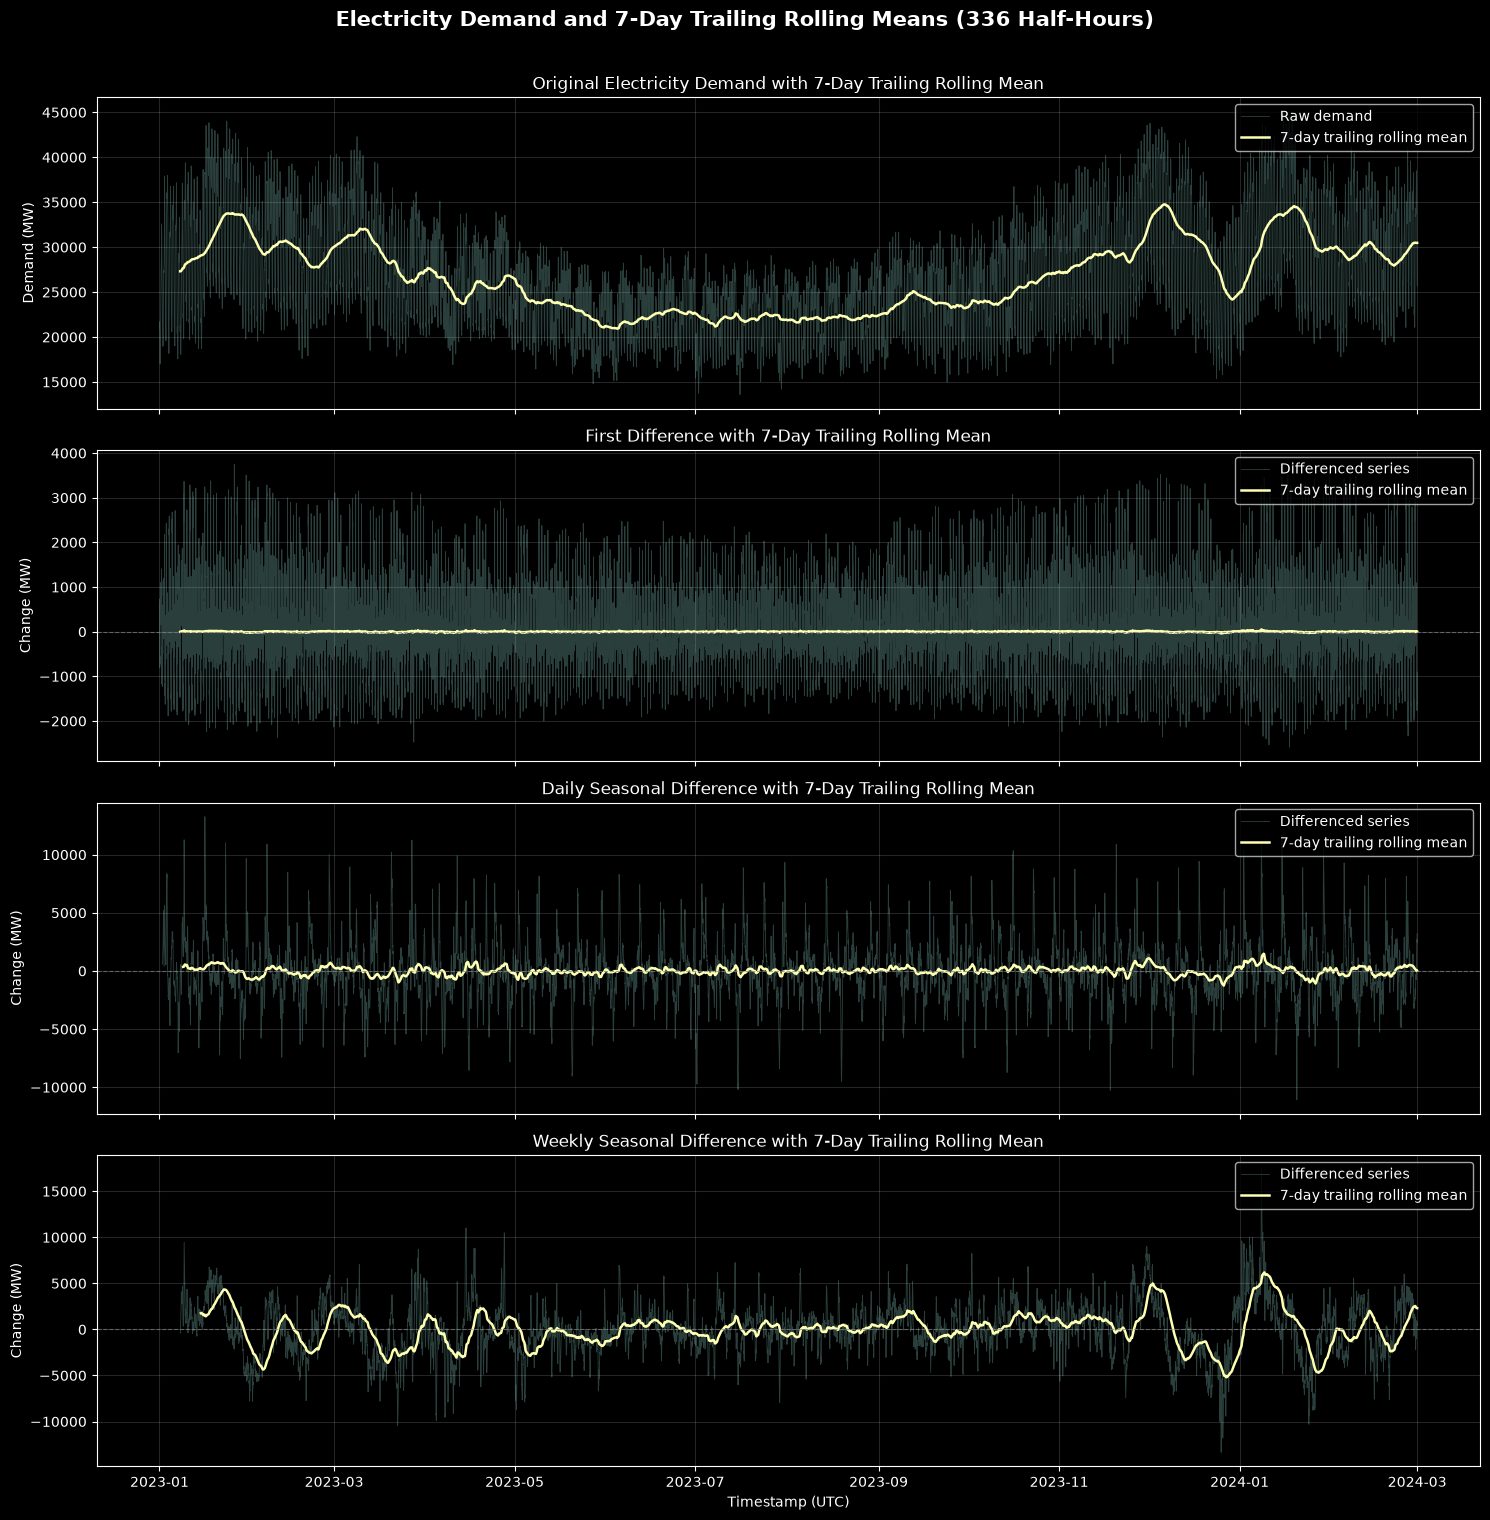

In [31]:
fig, axes = plt.subplots(4, 1, figsize=(15, 15), sharex=True)

series = [
    (demand_series, 'Original Electricity Demand', raw_data_rolling_mean, 'Raw Data Rolling Mean'),
    (first_diff, 'First Difference', first_diff_rolling_mean, 'First Difference Rolling Mean'),
    (daily_diff, 'Daily Seasonal Difference', daily_diff_rolling_mean, 'Daily Seasonal Difference Rolling Mean'),
    (weekly_diff, 'Weekly Seasonal Difference', weekly_diff_rolling_mean, 'Weekly Seasonal Difference Rolling Mean')
]

for i, (ax, (s, s_name, r, r_name)) in enumerate(zip(axes.flat, series)):
    ax.plot(
        s.index,
        s.values,
        linewidth=0.6,
        alpha=0.3,
        label='Raw demand' if i == 0 else 'Differenced series'
    )
    
    ax.plot(
        r.index,
        r.values,
        linewidth=1.8,
        label='7-day trailing rolling mean'
    )
    
    ax.set(
        title=f'{s_name} with 7-Day Trailing Rolling Mean',
        ylabel='Demand (MW)' if i == 0 else 'Change (MW)'
    )
    
    if i > 0:
        ax.axhline(
            0,
            color='gray',
            linestyle='--',
            alpha=0.7,
            linewidth=0.8
        )
    
    ax.legend(loc='upper right')
    ax.grid(alpha=0.15)
        
axes[-1].set_xlabel('Timestamp (UTC)')

fig.suptitle(
    'Electricity Demand and 7-Day Trailing Rolling Means (336 Half-Hours)',
    fontsize=15,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

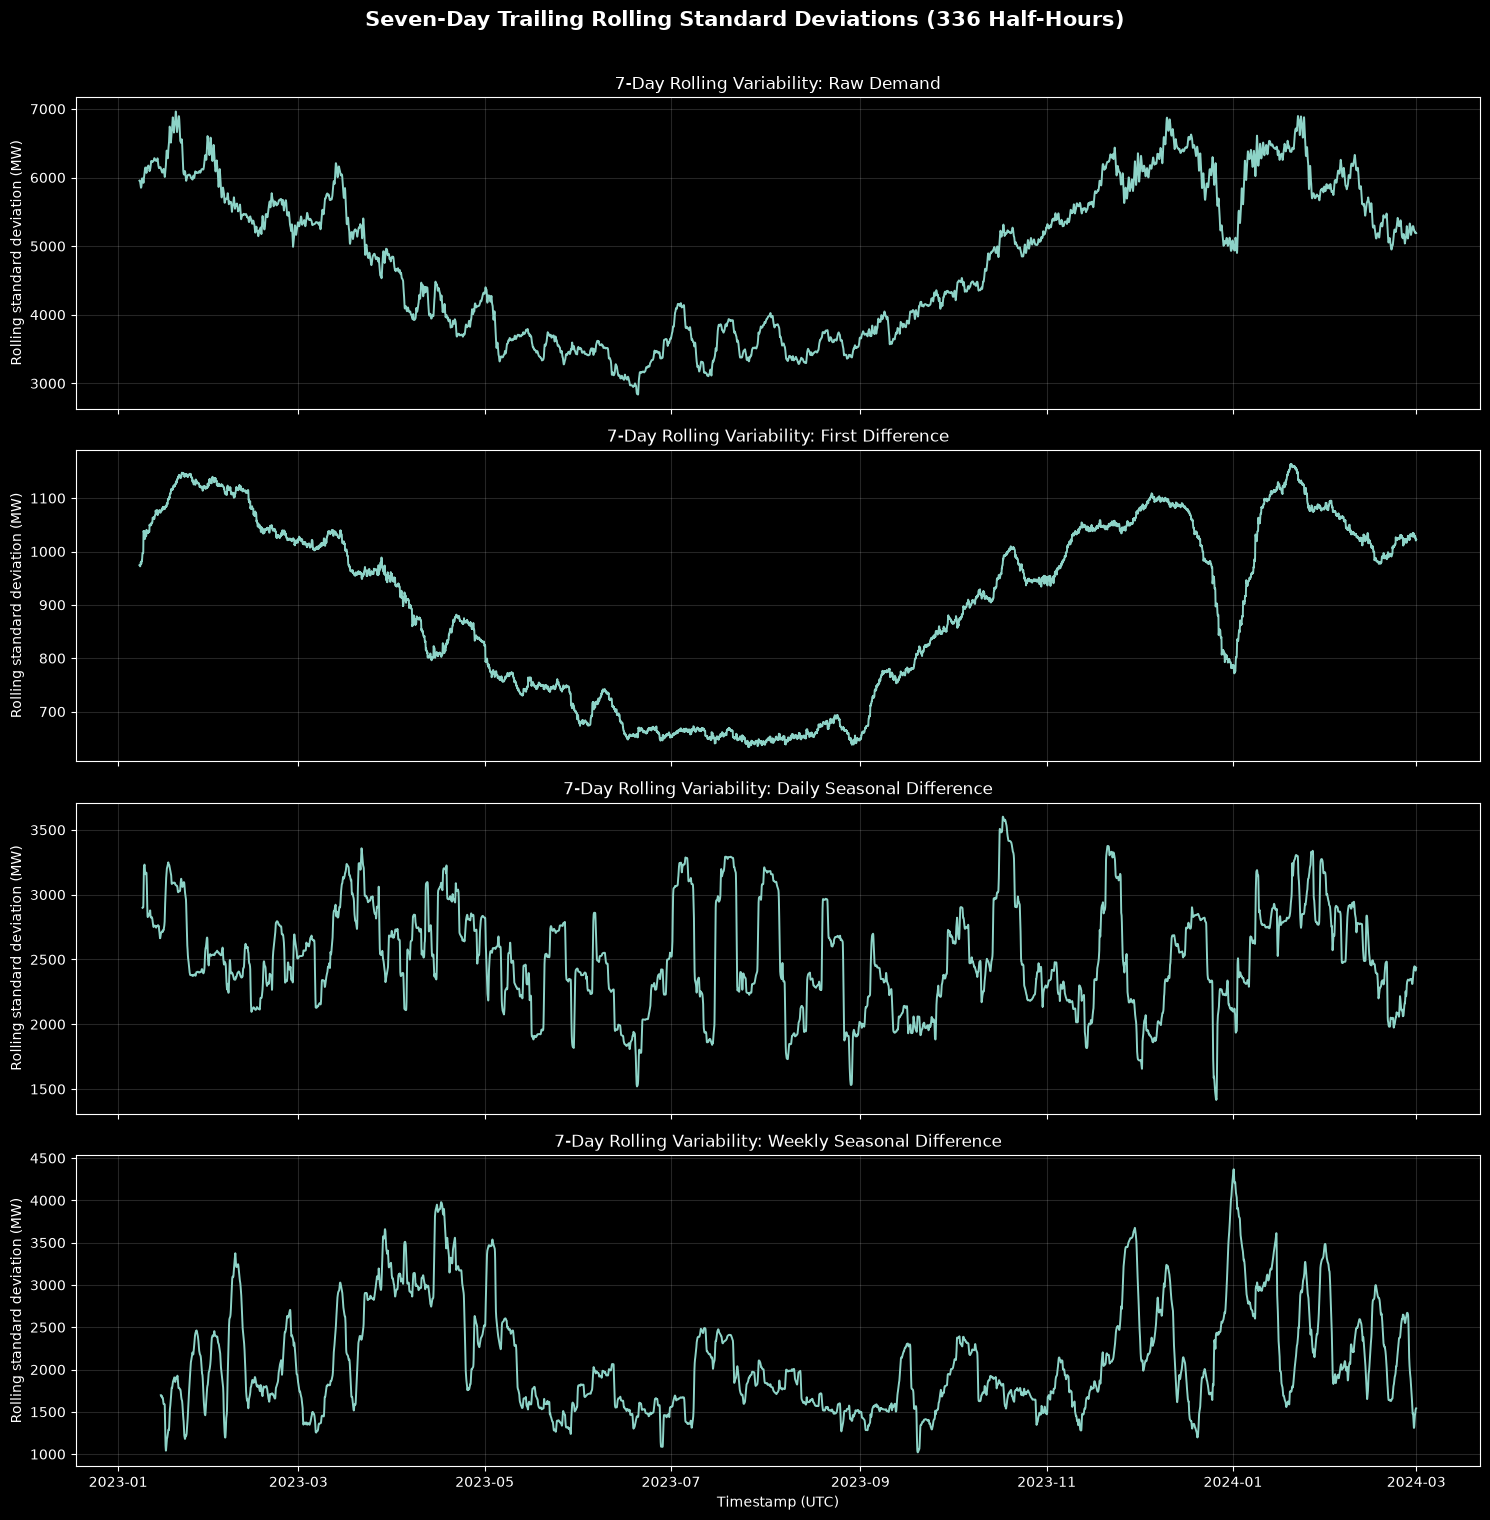

In [32]:
fig, axes = plt.subplots(4, 1, figsize=(15, 15), sharex=True)

rolling_std_series = [
    (raw_data_rolling_std, 'Raw Demand'),
    (first_diff_rolling_std, 'First Difference'),
    (daily_diff_rolling_std, 'Daily Seasonal Difference'),
    (weekly_diff_rolling_std, 'Weekly Seasonal Difference')
]

for ax, (rolling_std, series_name) in zip(axes.flat, rolling_std_series):
    ax.plot(
        rolling_std.index,
        rolling_std.values,
        linewidth=1.4,
        label='7-day trailing rolling standard deviation'
    )
    
    ax.set(
        title=f'7-Day Rolling Variability: {series_name}',
        ylabel='Rolling standard deviation (MW)'
    )
    
    ax.grid(alpha=0.15)
        
axes[-1].set_xlabel('Timestamp (UTC)')

fig.suptitle(
    'Seven-Day Trailing Rolling Standard Deviations (336 Half-Hours)',
    fontsize=15,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

In [33]:
rolling_diagnostics = {
    'Raw demand': (raw_data_rolling_mean, raw_data_rolling_std),
    'First difference': (first_diff_rolling_mean, first_diff_rolling_std),
    'Daily difference': (daily_diff_rolling_mean, daily_diff_rolling_std),
    'Weekly difference': (weekly_diff_rolling_mean, weekly_diff_rolling_std)
}

rolling_diagnostics_summary = pd.DataFrame([
    {
        'Series': name,
        'Rolling mean minimum': rolling_mean.min(),
        'Rolling mean maximum': rolling_mean.max(),
        'Rolling std minimum': rolling_std.min(),
        'Rolling std maximum': rolling_std.max()
    }
    for name, (rolling_mean, rolling_std) in rolling_diagnostics.items()
]).set_index('Series').round(2)

rolling_diagnostics_summary

,Rolling mean minimum,Rolling mean maximum,Rolling std minimum,Rolling std maximum
Series,,,,
Raw demand,20918.62,34776.50,2836.86,6962.23
First difference,-39.72,51.75,633.34,1163.84
Daily difference,-1260.11,1477.33,1417.47,3601.84
Weekly difference,-5190.97,6187.26,1021.23,4367.85


### Observations from the rolling diagnostics

#### Raw demand

The raw-demand rolling mean changes substantially across the sample, falling from the winter portion into summer and rising again toward the following winter. Its seven-day mean ranges from approximately 20,919 MW to 34,777 MW. The rolling standard deviation also changes considerably, from about 2,837 MW to 6,962 MW. Raw demand therefore does not visually have a constant mean or variance. The recurring calendar pattern is predictable seasonality, but it still violates the simplest constant-parameter stationary description of the unadjusted series.

#### First difference

The first-difference rolling mean stays very close to zero, between approximately -40 MW and 52 MW. This is a major improvement in mean stability because adjacent half-hour changes largely cancel the changing demand level. Its rolling standard deviation is less stable, ranging from about 633 MW to 1,164 MW, with greater variability in some winter periods than in summer. The first difference is therefore the most stable-looking series in its local mean, but it still shows time-varying volatility and may retain daily dependence.

#### Daily seasonal difference

The daily-difference rolling mean moves between approximately -1,260 MW and 1,477 MW. Long positive or negative periods mean that demand can remain systematically above or below the corresponding time on the preceding day. Its rolling standard deviation ranges from about 1,417 MW to 3,602 MW, so variability is also not constant. Daily differencing removes part of the intraday level pattern, but differences between weekdays, weekends, weather and exceptional dates remain.

#### Weekly seasonal difference

The weekly-difference rolling mean has the widest movement, approximately -5,191 MW to 6,187 MW. It contains sustained positive and negative runs, especially around the winter and holiday periods, meaning that whole weeks can differ systematically from the week before. Its rolling standard deviation ranges from about 1,021 MW to 4,368 MW and displays pronounced volatility bursts. Weekly differencing removes ordinary weekday alignment, but it does not remove seasonal transitions, changing weather, holidays or other week-specific shocks.

#### Overall conclusion

The raw series is clearly unstable in both local level and variability. Differencing improves mean stability, most strongly for the first difference, but none of the plots proves full stationarity. A stationary process requires more than a near-zero rolling mean: its variance and lag-dependence should also remain stable. These rolling windows overlap heavily, so they are descriptive rather than independent evidence. We should next combine this visual evidence with ADF and Phillips-Perron tests and compare the ACFs of the transformed series before choosing a model transformation.

## Formal Stationarity Testing

#### Augmented Dickey–Fuller Unit-Root Test

In [34]:
from statsmodels.tsa.stattools import adfuller

In [36]:
series = [
    (demand_series, 'Original Electricity Demand'),
    (first_diff, 'First Difference'),
    (daily_diff, 'Daily Seasonal Difference'),
    (weekly_diff, 'Weekly Seasonal Difference')
]

In [39]:
results = []

for (s, s_name) in series:
    test_res = adfuller(
            x=s.dropna(),
            maxlag=336,
            regression='c',
            autolag='AIC',
            result_object=True
        )
    
    result = {
        'Series name': s_name,
        'ADF statistic': test_res.statistic,
        'p-value': test_res.pvalue,
        'Number of lags selected': test_res.lags,
        'Number of observations used': test_res.nobs,
        '1% critical value': test_res.critical_values['1%'],
        '5% critical value': test_res.critical_values['5%'],
        '10% critical value': test_res.critical_values['10%'],
        'Decision at 5%': 'Reject the unit-root null' if test_res.pvalue < 0.05 else 'Fail to reject the unit-root null'
    }
    
    results.append(result)

In [40]:
results = pd.DataFrame(results)
results

,Series name,ADF statistic,p-value,Number of lags selected,Number of observations used,1% critical value,5% critical value,10% critical value,Decision at 5%
0,Original Electricity Demand,-1.877777,3.425866e-01,336,20063,-3.430676,-2.861684,-2.566847,Fail to reject the unit-root null
1,First Difference,-11.194102,2.329576e-20,336,20062,-3.430676,-2.861684,-2.566847,Reject the unit-root null
2,Daily Seasonal Difference,-8.675945,4.416109e-14,336,20015,-3.430677,-2.861684,-2.566847,Reject the unit-root null
3,Weekly Seasonal Difference,-6.332286,2.886623e-08,336,19727,-3.430682,-2.861687,-2.566848,Reject the unit-root null


- Raw demand has p=0.3426, so we fail to reject the unit-root null at 5%.
- First, daily and weekly differences all have extremely small p-values, so we reject the unit-root null for them.
- All four tests selected the maximum permitted 336 lags. Therefore, lag selection reached its boundary and the results require caution.
- Rejecting a unit root does not establish complete stationarity because seasonality, changing variance and structural changes may remain.